In [24]:
import shutil
import os
import glob

import numpy as np
import matplotlib.pyplot as plt
import cv2
from tqdm import tqdm

In [12]:
img_path = '../../../db/ObjectDetectionV2/data/datasets/baseline/train/images/PG1_CIR_H270_office_HotDesk_13_11_26_42_OS_2016.avi_snapshot_12.02.946.bmp'

In [13]:
img = cv2.imread(img_path)
img.shape

(960, 1280, 3)

In [14]:
with open(img_path.replace("images", 'labels').replace(".bmp", ".txt"), 'rt') as f:
    tmp_lines = f.readlines()

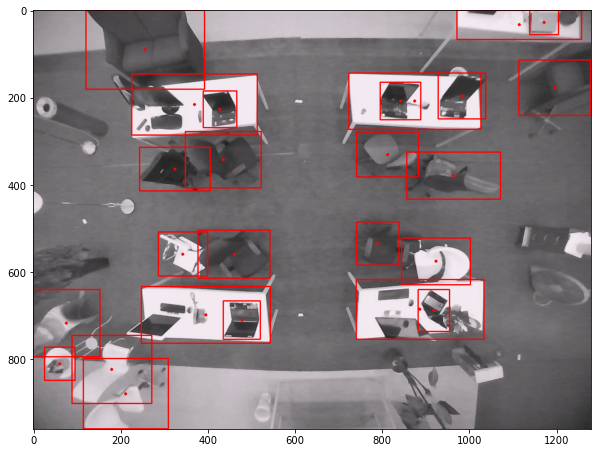

In [15]:
h, w, _ = img.shape
for line in tmp_lines:
    data = [float(i) for i in line.split(' ')]
    
    cv2.circle(img, (int(data[1] * w), int(data[2] * h)), 2, (255, 0, 0), 2)
    
    x = int((data[1] - data[3] / 2) * w)
    y = int((data[2] - data[4] / 2) * h)
    
    x2 = int((data[1] + data[3] / 2) * w)
    y2 = int((data[2] + data[4] / 2) * h)
    cv2.rectangle(img, (x, y), (x2, y2), (255, 0, 0), 2)

plt.figure(figsize=(10, 10))
plt.imshow(img)

In [17]:
train_path = '../../../db/ObjectDetectionV2/data/datasets/baseline/train/images'
val_path = '../../../db/ObjectDetectionV2/data/datasets/baseline/valid/images'
test_path = '../../../db/ObjectDetectionV2/data/datasets/baseline/test/images'

In [21]:
paths = glob.glob(os.path.join(train_path, '*'))


In [22]:
os.path.basename(paths[0])

'PG1_DL_H255_Office_Desk_empty_PG_1499758234.avi_snapshot_00.01.816.bmp'

In [27]:
def create_yolo_dataset(paths, task):
    base_path = "../../../db/ObjectDetectionV2/data/datasets/yolov7"
    img_path = os.path.join(base_path, "images", task)
    label_path = os.path.join(base_path, "labels", task)
    
    shutil.rmtree(img_path, ignore_errors=True)
    os.makedirs(img_path, exist_ok=True)
    shutil.rmtree(label_path, ignore_errors=True)
    os.makedirs(label_path, exist_ok=True)
    
    for path in tqdm(paths):
        img_name = os.path.basename(path).replace('.bmp', '.jpg').replace('.png', '.jpg').replace('.jpeg', '.jpg')
        img = cv2.imread(path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        img = cv2.resize(img, (640, 480))
        cv2.imwrite(os.path.join(img_path, img_name), cv2.cvtColor(img, cv2.COLOR_GRAY2BGR))
        
        shutil.copy(
            path.replace("images", 'labels').replace('.bmp', '.txt').replace('.png', '.txt').replace('.jpeg', '.txt'),
            os.path.join(label_path, img_name.replace('.jpg', '.txt'))
        )

In [28]:
create_yolo_dataset(glob.glob(os.path.join(train_path, '*')), 'train')

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 852/852 [00:06<00:00, 129.45it/s]


In [29]:
create_yolo_dataset(glob.glob(os.path.join(val_path, '*')), 'valid')

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 95/95 [00:00<00:00, 120.57it/s]


In [30]:
create_yolo_dataset(glob.glob(os.path.join(test_path, '*')), 'test')

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 54/54 [00:00<00:00, 114.15it/s]


(480, 640, 3)


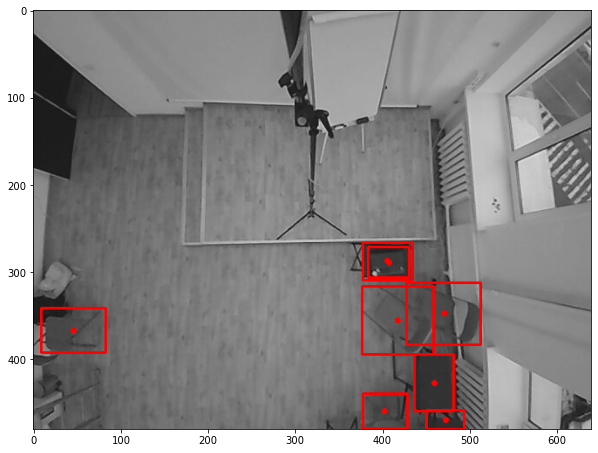

In [32]:
img_path = '../../../db/ObjectDetectionV2/data/datasets/yolov7/images/valid/H346_Cam2_Conference_20fps_dev2_20211201_152823.avi_snapshot_00.02.099.jpg'

img = cv2.imread(img_path)
print(img.shape)

with open(img_path.replace("images", 'labels').replace(".jpg", ".txt"), 'rt') as f:
    tmp_lines = f.readlines()
    
h, w, _ = img.shape
for line in tmp_lines:
    data = [float(i) for i in line.split(' ')]
    
    cv2.circle(img, (int(data[1] * w), int(data[2] * h)), 2, (255, 0, 0), 2)
    
    x = int((data[1] - data[3] / 2) * w)
    y = int((data[2] - data[4] / 2) * h)
    
    x2 = int((data[1] + data[3] / 2) * w)
    y2 = int((data[2] + data[4] / 2) * h)
    cv2.rectangle(img, (x, y), (x2, y2), (255, 0, 0), 2)

plt.figure(figsize=(10, 10))
plt.imshow(img)